练习1：航班乘客变化分析
分析年度乘客总量变化情况（折线图）
分析乘客在一年中各月份的分布（柱状图）

   year     month  passengers
0  1949   January         112
1  1949  February         118
2  1949     March         132
3  1949     April         129
4  1949       May         121
数据形状： (144, 3)
month  April  August  December  February  January  July  June  March  May  \
year                                                                        
1949     129     148       118       118      112   148   135    132  121   
1950     135     170       140       126      115   170   149    141  125   
1951     163     199       166       150      145   199   178    178  172   
1952     181     242       194       180      171   230   218    193  183   
1953     235     272       201       196      196   264   243    236  229   
1954     227     293       229       188      204   302   264    235  234   
1955     269     347       278       233      242   364   315    267  270   
1956     313     405       306       277      284   413   374    317  318   
1957     348     467       336     

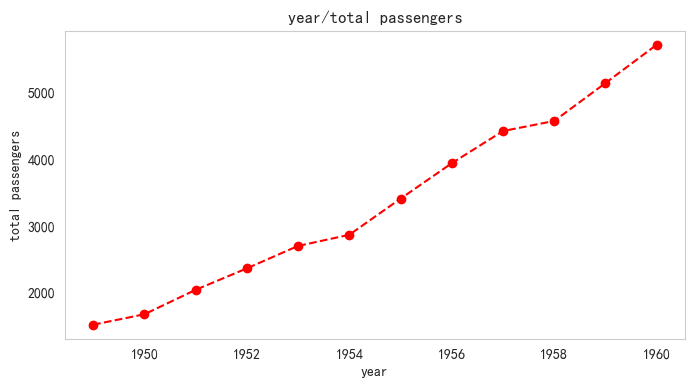

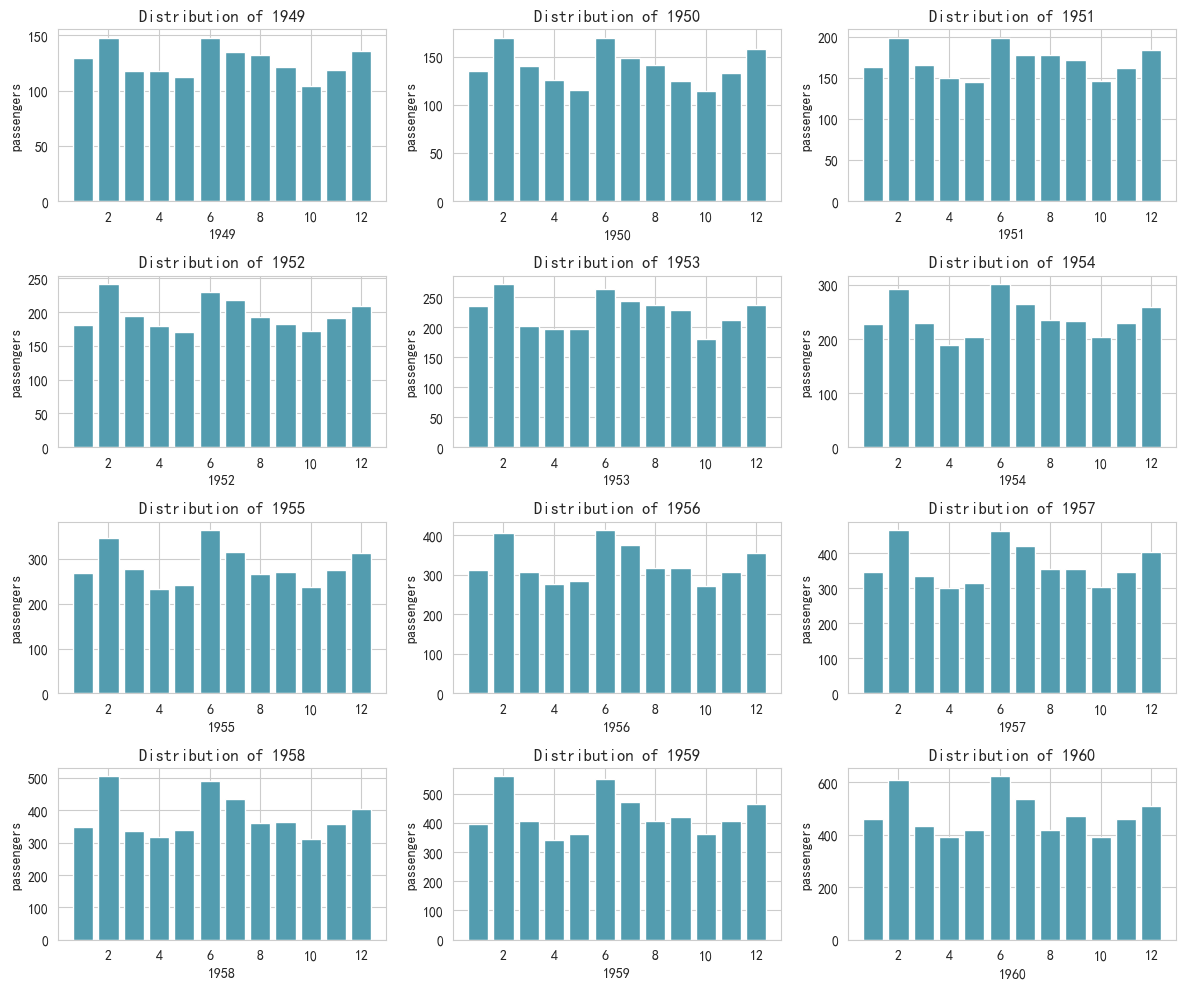

In [12]:
%matplotlib inline
import matplotlib as mpl
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

# 设置中文（不需要可注释掉）
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ----从U盘读取csv（用r""原始字符串防止反斜杠转义）----
file_path = r"G:\研一数据仓库\实验一\flights.csv"
data = pd.read_csv(file_path)
print(data.head())
print("数据形状：", data.shape)

# 年份，月份，乘客数
by_year_month = data.groupby(['year','month'])
by_year_month_data = by_year_month.passengers.sum().unstack(1)
print(by_year_month_data)

# 每年总乘客数（修复原代码total未定义bug）
total = by_year_month_data.sum(axis=1)
x = by_year_month_data.index
y = total.values

# 年度总乘客折线图
plt.figure(figsize=(8,4))
plt.plot(x, y, 'ro--')
plt.xlabel('year')
plt.ylabel('total passengers')
plt.title('year/total passengers')
plt.grid()
plt.show()

# 分年份子图：每年1‑12月乘客柱状图
plt.figure(figsize=(12,10))
for i in range(1949,1961):
    x_data = range(1,13)
    y_data = by_year_month_data.loc[i].values
    data_color = '#539caf'
    x_label = '%s' % i
    y_label = 'passengers'
    title = 'Distribution of %s' % i

    ite = i - 1948
    plt.subplot(4,3,ite)
    plt.bar(x_data, y_data, color = '#539caf', align = 'center')
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)

plt.tight_layout()
plt.show()


   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
列名： ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
种类： ['setosa' 'versicolor' 'virginica']


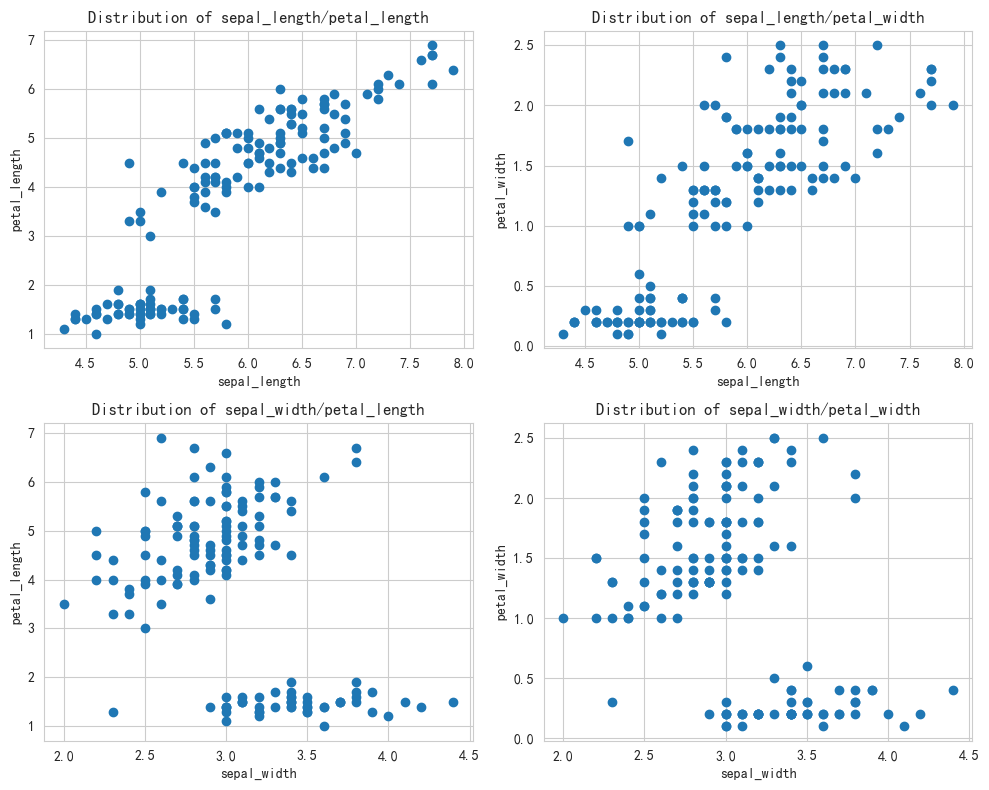

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


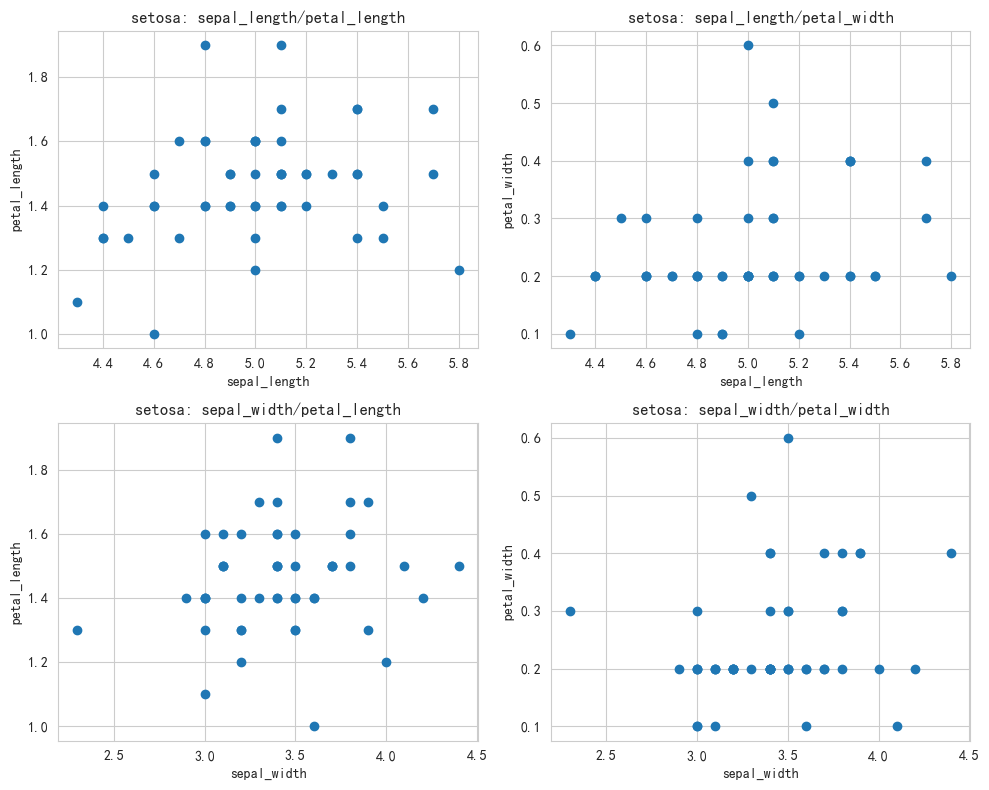

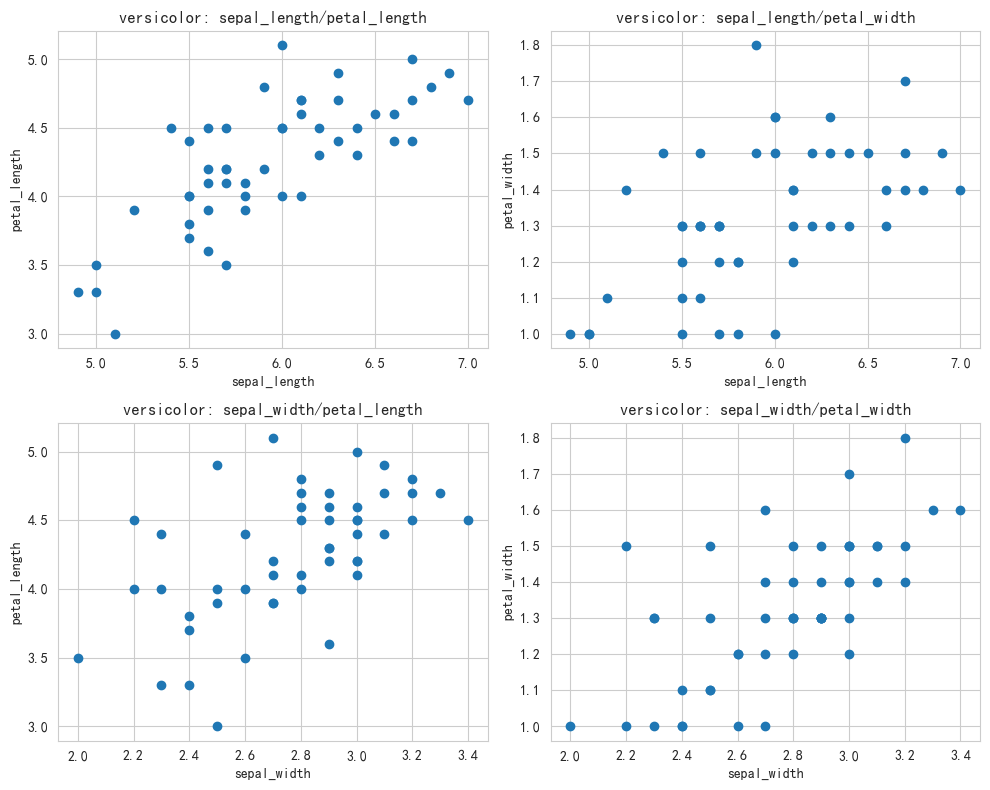

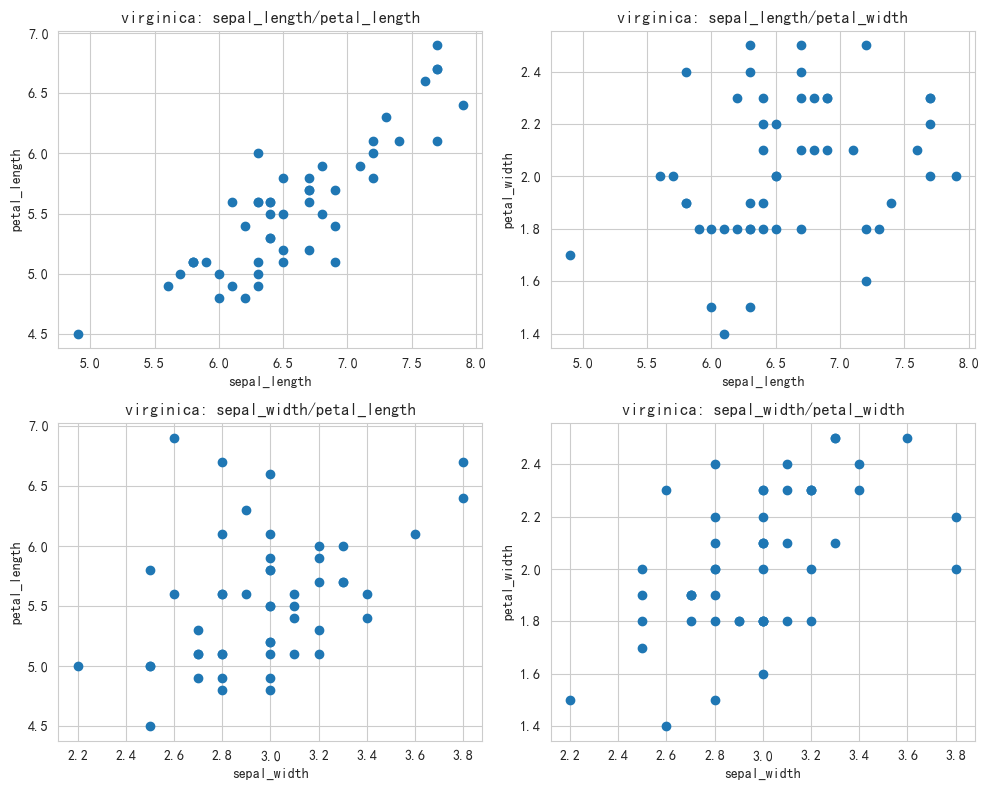

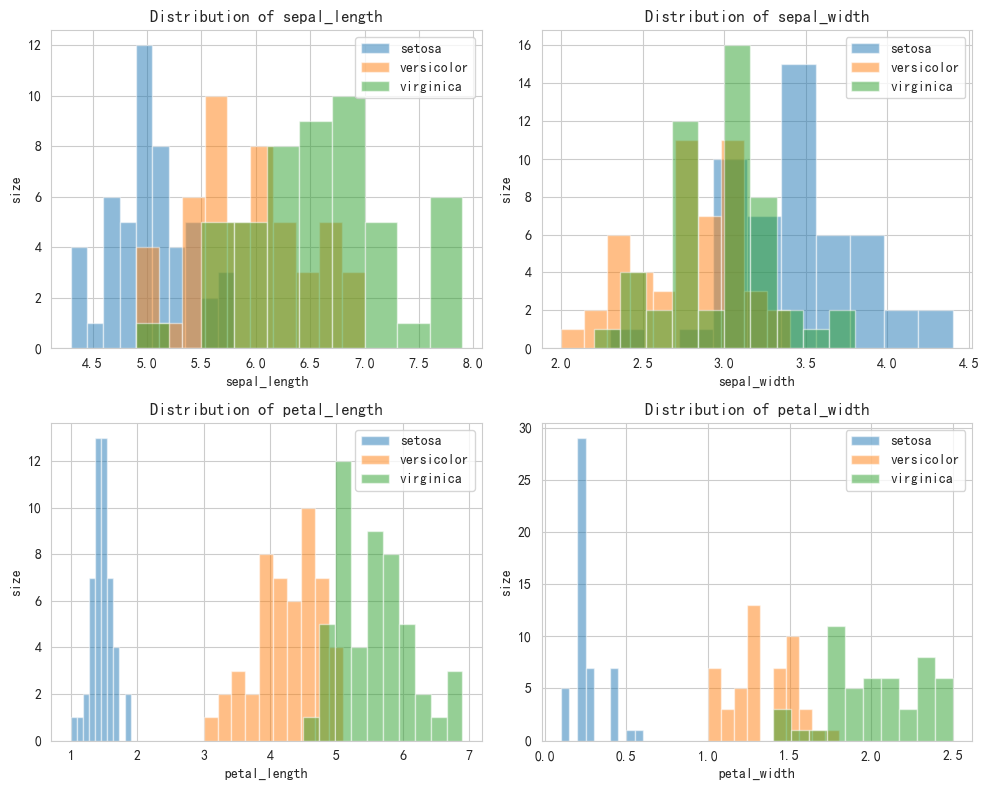

In [14]:
%matplotlib inline
import matplotlib as mpl
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ----从U盘读取iris.csv（seaborn内置iris数据，内容一致）----
file_path = r"G:\研一数据仓库\实验一\iris.csv"
data = pd.read_csv(file_path)
print(data.head())
print("列名：", data.columns.tolist())
print("种类：", data['species'].unique())

# ============ 一、萼片与花瓣大小关系（散点子图，4个组合）============
def scattergram(data, x_label, y_label, title, i):
    x = data[x_label]
    y = data[y_label]
    plt.subplot(2,2,i)
    res = plt.scatter(x,y)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    return res

plt.figure(figsize=(10,8))
res = scattergram(data, x_label='sepal_length', y_label='petal_length',
                  title='Distribution of sepal_length/petal_length', i=1)
res = scattergram(data, x_label='sepal_length', y_label='petal_width',
                  title='Distribution of sepal_length/petal_width', i=2)
res = scattergram(data, x_label='sepal_width',  y_label='petal_length',
                  title='Distribution of sepal_width/petal_length',  i=3)
res = scattergram(data, x_label='sepal_width',  y_label='petal_width',
                  title='Distribution of sepal_width/petal_width',  i=4)
plt.tight_layout()
plt.show()

# ============ 二、不同种类萼片花瓣关系（分类散点子图）============
species_data = data.set_index(['species'])
print(species_data.index.value_counts())

# 三种类分别绘制4组合散点子图
for species_name in ['setosa', 'versicolor', 'virginica']:
    plt.figure(figsize=(10,8))
    # 4个变量组合
    combos = [('sepal_length','petal_length'), ('sepal_length','petal_width'),
              ('sepal_width','petal_length'),  ('sepal_width','petal_width')]
    for idx, (xname, yname) in enumerate(combos, start=1):
        subdata = species_data.loc[species_name, (xname, yname)]
        plt.subplot(2,2,idx)
        plt.scatter(subdata[xname], subdata[yname])
        plt.xlabel(xname)
        plt.ylabel(yname)
        plt.title('%s: %s/%s' % (species_name, xname, yname))
    plt.tight_layout()
    plt.show()

# ============ 三、不同种类萼片花瓣大小分布（直方图，整体4特征）============
species_data2 = data.set_index(['species'])
fig, axes = plt.subplots(2,2, figsize=(10,8))
features = [('sepal_length','sepal_length'), ('sepal_width','sepal_width'),
            ('petal_length','petal_length'),  ('petal_width','petal_width')]
for idx, (feat, label) in enumerate(features):
    ax = axes[idx//2, idx%2]
    for sp in ['setosa','versicolor','virginica']:
        vals = species_data2.loc[sp, feat]
        ax.hist(vals, bins=10, alpha=0.5, label=sp)
    ax.set_xlabel(label)
    ax.set_ylabel('size')
    ax.set_title('Distribution of %s' % label)
    ax.legend()
plt.tight_layout()
plt.show()




   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
列名： ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']


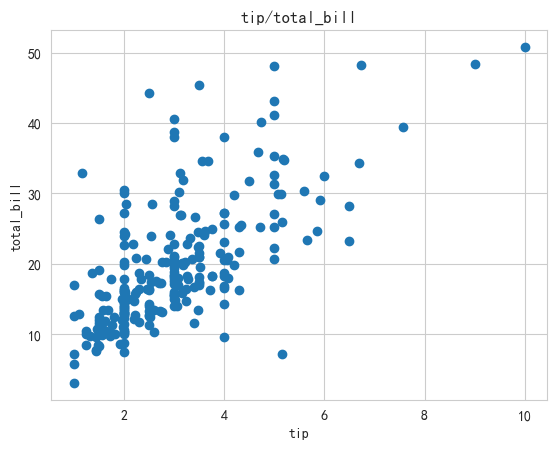

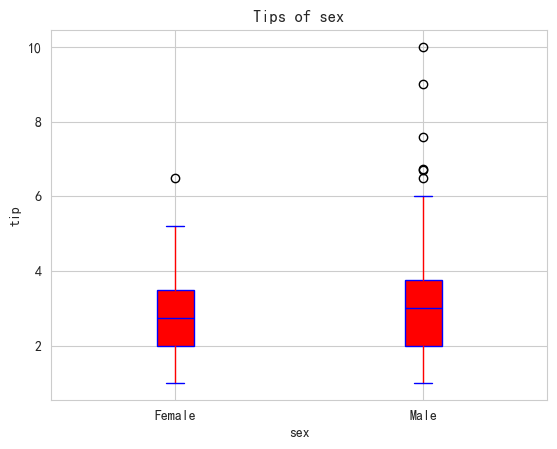

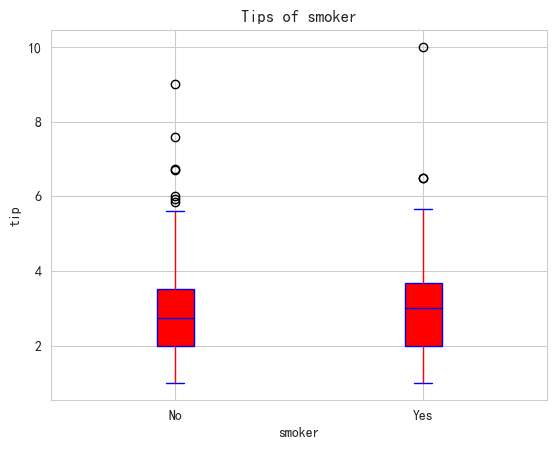

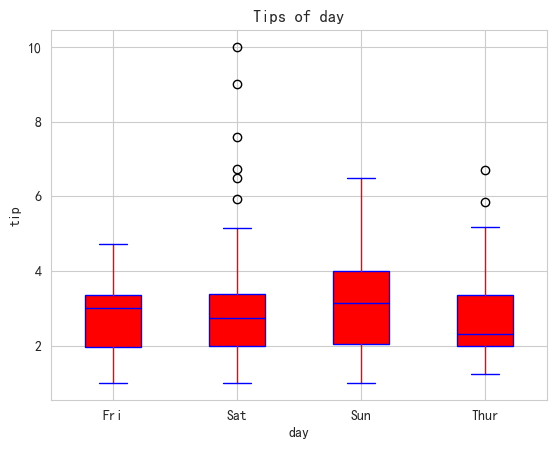

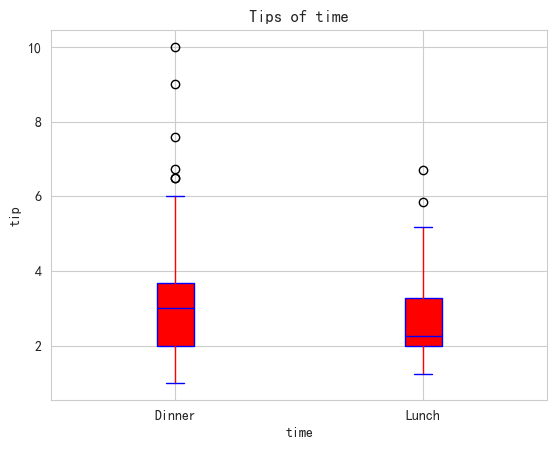

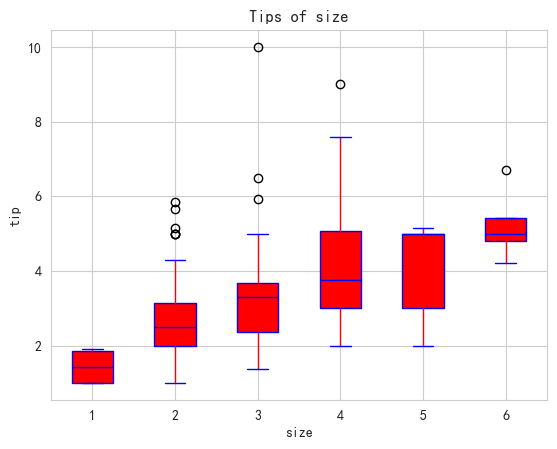

      sex smoker       tip
0  Female     No  2.773519
1  Female    Yes  2.931515
2    Male     No  3.113402
3    Male    Yes  3.051167


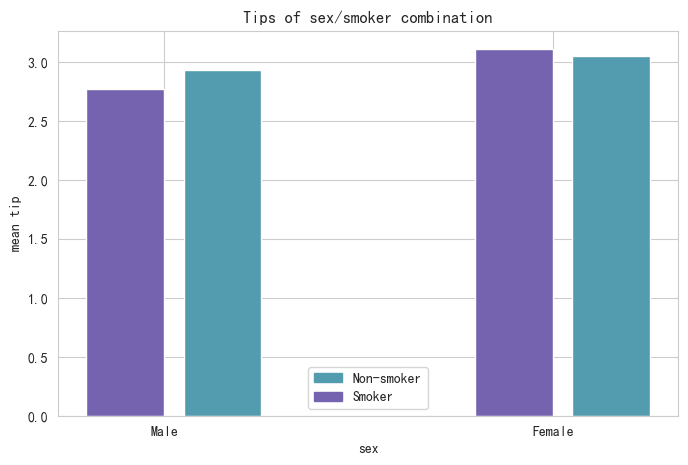

In [15]:
%matplotlib inline
import matplotlib as mpl
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ----从U盘读取tips.csv----
file_path = r"G:\研一数据仓库\实验一\tips.csv"
data = pd.read_csv(file_path)
print(data.head())
print("列名：", data.columns.tolist())

# ============ 一、小费与总消费散点图 ============
x = data['tip']
y = data['total_bill']
plt.scatter(x, y)
plt.xlabel('tip')
plt.ylabel('total_bill')
plt.title('tip/total_bill')
plt.show()

# ============ 二、通用箱线图函数（只定义一次）============
def boxplot(x_data, y_data, base_color='b', median_color='r',
            x_label='', y_label='', title=''):
    _, ax = plt.subplots()
    ax.boxplot(y_data
               , patch_artist = True
               , medianprops = {'color': base_color}
               , boxprops = {'color': base_color, 'facecolor': median_color}
               , whiskerprops = {'color': median_color}
               , capprops = {'color': base_color})
    ax.set_xticklabels(x_data)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)
    plt.show()

def tips_by(column, x_label, title):
    groups = np.unique(data[column])
    group_data = [data[data[column]==g]['tip'].values for g in groups]
    boxplot(x_data=groups, y_data=group_data, x_label=x_label,
            y_label='tip', title=title)
    return groups, group_data

# ============ 三、五个维度的分类箱线图 ============
# 1. 男女谁更慷慨
sexs, _ = tips_by('sex', 'sex', 'Tips of sex')
# 2. 是否抽烟对小费影响
smokers, _ = tips_by('smoker', 'smoker', 'Tips of smoker')
# 3. 工作日/周末哪天更慷慨
days, _ = tips_by('day', 'day', 'Tips of day')
# 4. 午饭/晚饭哪顿更慷慨
times, _ = tips_by('time', 'time', 'Tips of time')
# 5. 就餐人数对慷慨度影响
sizes, _ = tips_by('size', 'size', 'Tips of size')

# ============ 四、性别+抽烟组合对慷慨度的影响（分组柱状图）============
# 按(sex, smoker)分组求小费均值
subdata = data[['sex','smoker','tip']].groupby(['sex','smoker']).mean().reset_index()
print(subdata)

# 定义每个组合的x位置和颜色
positions = [0, 0.25, 1, 1.25]
colors = ['#7663b0', '#539caf', '#7663b0', '#539caf']  # No/Yes 用不同色区分

plt.figure(figsize=(8,5))
for i, row in subdata.iterrows():
    plt.bar(positions[i], row['tip'], width=0.2, color=colors[i], align='center')

# 用sex作为大组标签（Male/Female），smoker用小标签
plt.xticks([0.1, 1.1], ['Male', 'Female'])
plt.xlabel('sex')
plt.ylabel('mean tip')
plt.title('Tips of sex/smoker combination')

# 图例（用smoker颜色标识）
import matplotlib.patches as mpatches
patch_no = mpatches.Patch(color='#539caf', label='Non-smoker')
patch_yes = mpatches.Patch(color='#7663b0', label='Smoker')
plt.legend(handles=[patch_no, patch_yes])
plt.show()


   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
pclass幸存比例: [0.63, 0.47, 0.24]


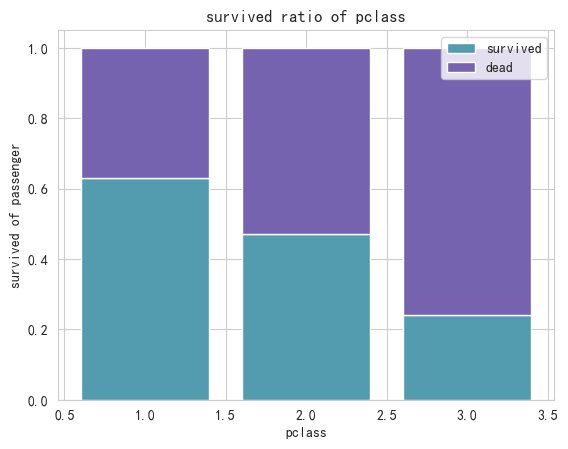

sex幸存比例: [0.74, 0.19]


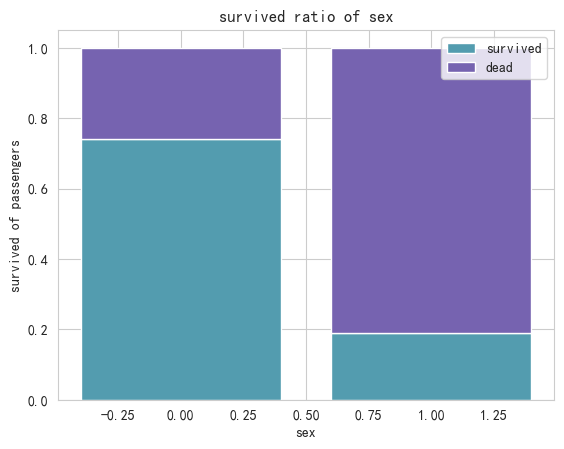

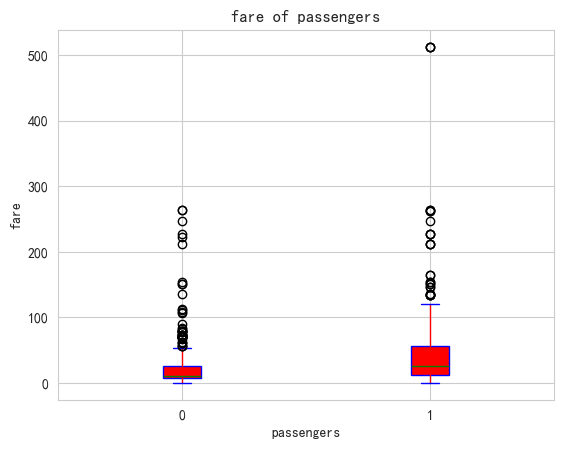

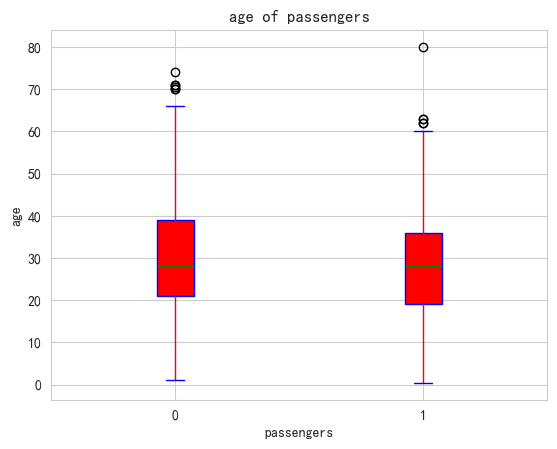

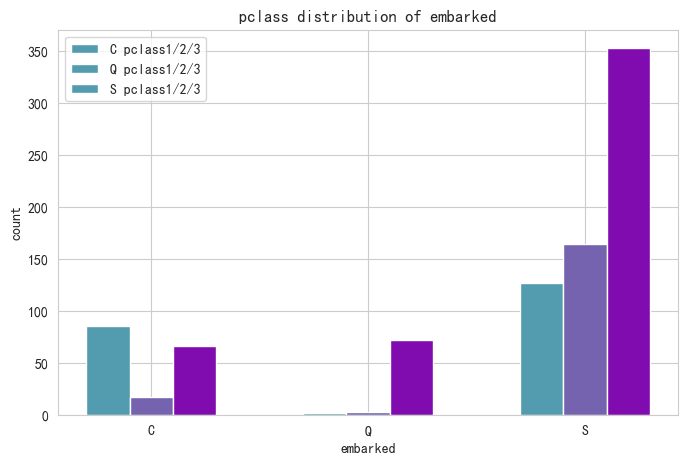

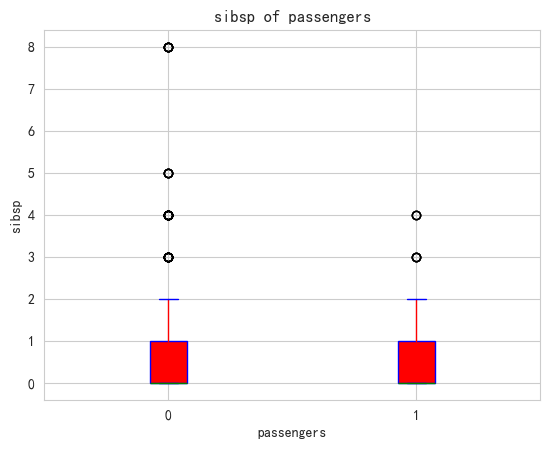

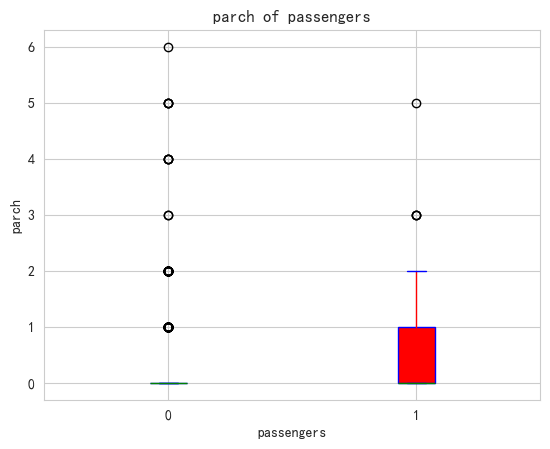

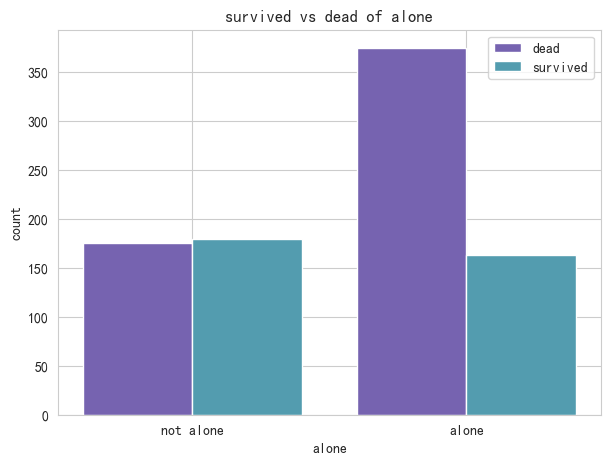

In [16]:
%matplotlib inline
import matplotlib as mpl
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

file_path = r"G:\研一数据仓库\实验一\titanic.csv"

# 加载数据（每次重新读取，保持data干净）
def load_data():
    return pd.read_csv(file_path)

# ============ 通用函数定义 ============
def survived_ratio_for(column):
    """按某列分组，计算每组幸存比例"""
    groups = np.unique(data[column])
    group_data = [data[data[column]==g]['survived'].values for g in groups]
    y1 = []
    for i in range(len(group_data)):
        temp_ratio = float(group_data[i].sum(0))/len(group_data[i])
        y1.append(float('%.2f' % temp_ratio))
    y2 = [1-i for i in y1]
    return groups, y1, y2

def stackedbarplot(x_data, y_data_list, y_data_names, colors, x_label, y_label, title):
    _, ax = plt.subplots()
    for i in range(0, len(y_data_list)):
        if i == 0:
            ax.bar(x_data, y_data_list[i], color=colors[i], align='center', label=y_data_names[i])
        else:
            ax.bar(x_data, y_data_list[i], color=colors[i], bottom=y_data_list[i-1],
                   align='center', label=y_data_names[i])
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)
    ax.legend(loc='upper right')
    plt.show()

def boxplot(x_data, y_data, x_label, y_label, title):
    _, ax = plt.subplots()
    ax.boxplot(y_data, patch_artist=True,
               medianprops={'color': 'g'},
               boxprops={'color': 'b', 'facecolor': 'r'},
               whiskerprops={'color': 'r'},
               capprops={'color': 'b'})
    ax.set_xticklabels(x_data)
    ax.set_ylabel(y_label)
    ax.set_xlabel(x_label)
    ax.set_title(title)
    plt.show()

# ============ 1. 不同仓位等级幸存/遇难比例（堆积柱状图）============
data = load_data()
print(data.head())
x, y1, y2 = survived_ratio_for('pclass')
print("pclass幸存比例:", y1)
stackedbarplot(x, [y1,y2], ['survived','dead'], ['#539caf','#7663b0'],
               'pclass', 'survived of passenger', 'survived ratio of pclass')

# ============ 2. 不同性别幸存比例（堆积柱状图）============
data = load_data()
x, y1, y2 = survived_ratio_for('sex')
print("sex幸存比例:", y1)
stackedbarplot([0,1], [y1,y2], ['survived','dead'], ['#539caf','#7663b0'],
               'sex', 'survived of passengers', 'survived ratio of sex')
plt.show()

# ============ 3. 幸存/遇难乘客票价分布（分类箱线图）============
data = load_data()
passengers = np.unique(data['survived'])
fare_data = [data[data['survived']==p]['fare'].values for p in passengers]
boxplot(passengers, fare_data, 'passengers', 'fare', 'fare of passengers')

# ============ 4. 幸存/遇难乘客年龄分布（分类箱线图，去掉缺失年龄）============
data = load_data()
temp_data = data.loc[:, ('survived','age')].dropna(axis=0, how='any')
passengers = np.unique(temp_data['survived'])
age_data = [temp_data[temp_data['survived']==p]['age'].values for p in passengers]
boxplot(passengers, age_data, 'passengers', 'age', 'age of passengers')

# ============ 5. 不同上船港口的乘客仓位等级分布（分组柱状图）============
data = load_data()
temp_data = data.loc[:, ('embarked','pclass')].dropna(axis=0, how='any')
ports = np.unique(temp_data['embarked'])
x = ports
port_data = [temp_data[temp_data['embarked']==p]['pclass'].values for p in ports]

port_data_pclass = []
for i in range(len(port_data)):
    counts = [0,0,0]
    for v in port_data[i]:
        if v == 1: counts[0] += 1
        elif v == 2: counts[1] += 1
        elif v == 3: counts[2] += 1
    port_data_pclass.append(counts)

plt.figure(figsize=(8,5))
colors = ['#539caf','#7663b0','#800caf']
for i in range(len(ports)):
    # 每个港口画3根柱，对应 pclass 1/2/3
    plt.bar(np.array([0,0.2,0.4]) + i*1.0, port_data_pclass[i],
            color=colors, width=0.2, align='center',
            label=('%s pclass1/2/3' % ports[i]))
plt.xticks([0.2,1.2,2.2], ports)
plt.xlabel('embarked')
plt.ylabel('count')
plt.title('pclass distribution of embarked')
plt.legend()
plt.show()

# ============ 6. 幸存/遇难乘客堂兄弟姐妹数量分布（分类箱线图）============
data = load_data()
temp_data = data.loc[:, ('survived','sibsp')].dropna(axis=0, how='any')
passengers = np.unique(temp_data['survived'])
sibsp_data = [temp_data[temp_data['survived']==p]['sibsp'].values for p in passengers]
boxplot(passengers, sibsp_data, 'passengers', 'sibsp', 'sibsp of passengers')

# ============ 7. 幸存/遇难乘客父母子女数量分布（分类箱线图）============
data = load_data()
temp_data = data.loc[:, ('survived','parch')].dropna(axis=0, how='any')
passengers = np.unique(temp_data['survived'])
parch_data = [temp_data[temp_data['survived']==p]['parch'].values for p in passengers]
boxplot(passengers, parch_data, 'passengers', 'parch', 'parch of passengers')

# ============ 8. 单独乘船与否与幸存的关系（分组柱状图）============
data = load_data()
temp_data = data.loc[:, ('survived','alone')].dropna(axis=0, how='any')
alone_states = np.unique(temp_data['alone'])   # True/False
alone_data = [temp_data[temp_data['alone']==a]['survived'].values for a in alone_states]

# 修复老师bug：统计每组里幸存(1)和遇难(0)的人数，count每组内要归零
alone_data_counts = [[],[]]
for i in range(len(alone_data)):
    c0 = (alone_data[i]==0).sum()   # 遇难
    c1 = (alone_data[i]==1).sum()   # 幸存
    alone_data_counts[0].append(c0)
    alone_data_counts[1].append(c1)

plt.figure(figsize=(7,5))
# 遇难柱 + 幸存柱并排
plt.bar([0,1], alone_data_counts[0], color='#7663b0', width=0.4, align='center', label='dead')
plt.bar([0.4,1.4], alone_data_counts[1], color='#539caf', width=0.4, align='center', label='survived')
plt.xticks([0.2,1.2], ['not alone', 'alone'])
plt.xlabel('alone')
plt.ylabel('count')
plt.title('survived vs dead of alone')
plt.legend()
plt.show()


词云生成成功！


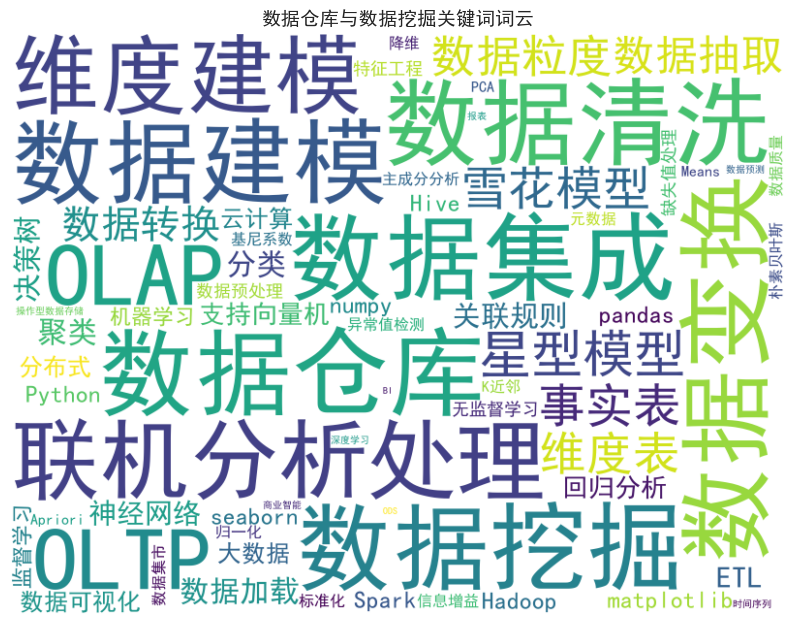

In [17]:
# 导入库
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import os

# 设置中文字体（解决中文乱码）
plt.rcParams['font.sans-serif'] = ['SimHei']  # 黑体
plt.rcParams['axes.unicode_minus'] = False    # 负号正常显示

# 准备文本素材（数据仓库与数据挖掘课程关键词）
text_content = """
数据仓库 数据挖掘 数据清洗 数据变换 数据集成 数据建模
联机分析处理 OLAP OLTP 维度建模 星型模型 雪花模型
事实表 维度表 数据粒度 数据抽取 数据转换 数据加载 ETL
分类 聚类 关联规则 决策树 神经网络 支持向量机 回归分析
数据可视化 matplotlib seaborn pandas numpy Python
Hadoop Hive Spark 大数据 分布式 云计算 机器学习
监督学习 无监督学习 特征工程 数据预处理 缺失值处理
异常值检测 标准化 归一化 主成分分析 PCA 降维
信息增益 基尼系数 朴素贝叶斯 K近邻 K-Means Apriori
数据质量 元数据 数据集市 操作型数据存储 ODS
商业智能 BI 报表 数据预测 时间序列 深度学习
"""

# 生成词云
wc = WordCloud(
    font_path=r'C:\Windows\Fonts\simhei.ttf',  # 中文字体路径
    width=800,          # 画布宽度
    height=600,         # 画布高度
    background_color='white',  # 背景颜色
    max_words=200,      # 最大词数
    max_font_size=100,  # 最大字号
    collocations=False  # 不计算双词组，避免重复
)

wc.generate(text_content)

# 保存词云图
wc.to_file('wordcloud.png')
print("词云生成成功！")

# 显示词云
plt.figure(figsize=(10, 8))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('数据仓库与数据挖掘关键词词云', fontsize=14)
plt.show()


数据集形状: (244, 7)
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


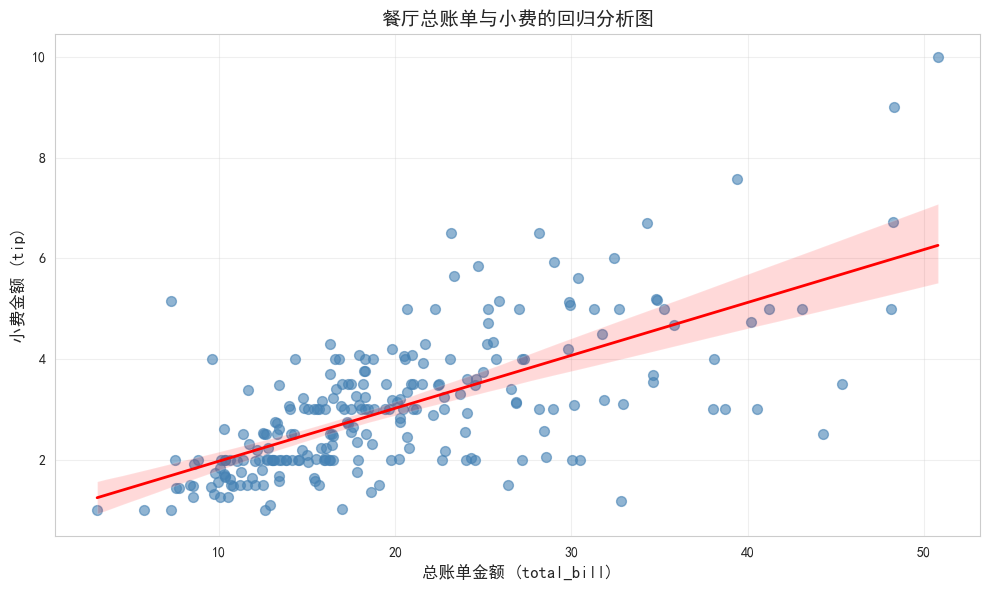

皮尔逊相关系数: 0.6757


In [18]:
# 导入库
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 加载tips数据集（餐厅小费数据）
# 方式1：从seaborn内置加载（需要联网）
# tips = sns.load_dataset("tips")

# 方式2：从本地CSV加载（推荐，你实验文件夹里已有tips.csv）
tips = pd.read_csv(r'G:\研一数据仓库\实验一\tips.csv')

# 查看数据
print("数据集形状:", tips.shape)
print(tips.head())

# 绘制带回归拟合线的散点图
plt.figure(figsize=(10, 6))
sns.regplot(
    x='total_bill',    # 总账单金额（x轴）
    y='tip',           # 小费金额（y轴）
    data=tips,
    scatter_kws={     # 散点样式
        's': 50,      # 点大小
        'alpha': 0.6, # 透明度
        'color': 'steelblue'  # 点颜色
    },
    line_kws={        # 回归线样式
        'color': 'red',   # 线颜色
        'linewidth': 2    # 线宽
    }
)

plt.title('餐厅总账单与小费的回归分析图', fontsize=14)
plt.xlabel('总账单金额 (total_bill)', fontsize=12)
plt.ylabel('小费金额 (tip)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# 保存图片
plt.savefig('regplot.png', dpi=150, bbox_inches='tight')
plt.show()

# 计算皮尔逊相关系数
corr = tips['total_bill'].corr(tips['tip'])
print(f"皮尔逊相关系数: {corr:.4f}")


In [19]:
import numpy as np
# 欧氏距离(Euclidean Distance)
def euclidean(x, y):
    return np.sqrt(np.sum((x - y) ** 2))
# 曼哈顿距离(Manhattan Distance)
def manhattan(x, y):
    return np.sum(np.abs(x - y))
# 切比雪夫距离(Chebyshev Distance)
def chebyshev(x, y):
    return np.max(np.abs(x - y))
# 闵可夫斯基距离(Minkowski Distance)
def minkowski(x, y, p):
    return np.sum(np.abs(x - y) ** p) ** (1/p)
# 汉明距离(Hamming Distance)
def hamming(x, y):
    return np.sum(x != y) / len(x)
# 余弦相似性
def cos_similarity(x, y):
    return np.dot(x, y) / (np.linalg.norm(x) * np.linalg.norm(y))


In [20]:
import numpy as np
from scipy.spatial.distance import pdist
x = (0.7, 0.9, 0.2, 0.3, 0.8, 0.4, 0.6, 0, 0.5)
y = (0.6, 0.8, 0.5, 0.4, 0.3, 0.5, 0.7, 0.2, 0.6)
X = np.vstack([x, y])
d1 = pdist(X, 'euclidean')
print('欧氏距离：', d1)
d2 = pdist(X, 'cityblock')
print('曼哈顿距离：', d2)
d3 = pdist(X, 'chebyshev')
print('切比雪夫距离：', d3)
d4 = pdist(X, 'minkowski', p = 2)
print('闵可夫斯基距离：', d4)
d5 = pdist(X, 'cosine')
print('余弦相似性：', 1 - d5)


欧氏距离： [0.66332496]
曼哈顿距离： [1.6]
切比雪夫距离： [0.5]
闵可夫斯基距离： [0.66332496]
余弦相似性： [0.92032116]


In [21]:
x = (0.7, 0.9, 0.2, 0.3, 0.8, 0.4, 0.6, 0, 0.5)
y = (0.6, 0.8, 0.5, 0.4, 0.3, 0.5, 0.7, 0.2, 0.6)
print('欧氏距离：', euclidean(x, y))
print('曼哈顿距离：', manhattan(x, y))
print('切比雪夫距离：', chebyshev(x, y))
print('闵可夫斯基距离：', minkowski(x, y, 2))
print('汉明距离：', hamming(x, y))
print('余弦相似性：', cos_similarity(x, y))


TypeError: unsupported operand type(s) for -: 'tuple' and 'tuple'